# 01 - Train Data EDA

We only look at `results/train.csv` in this notebook. `test.csv` is not used here.


In [1]:
# basic libraries for data and plots
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 80)
sns.set_theme(style="whitegrid")

# load only the train data
train_path = Path("..") / "results" / "train.csv"
df = pd.read_csv(train_path)
print("rows and columns:", df.shape)


rows and columns: (12534, 66)


## 1. First Look at the Data


In [2]:
# check first 5 rows
df.head()


,cycle,seqn,target,age,sex,education,income_poverty_ratio,marital_status,height_cm,weight_kg,bmi,waist_cm,waist_height_ratio,systolic_mean,diastolic_mean,pulse,work_activity_min_week,leisure_activity_min_week,transport_min_week,sedentary_min_day,smoking_status,cigarettes_per_smoking_day,alcohol_frequency,drinks_per_drinking_day,sleep_workday_hours,weight_1year_ago_kg,family_diabetes,energy_kcal,carbohydrate_g,protein_g,total_fat_g,total_sugar_g,fiber_g,nightly_urination_count_5plus,plain_water_day1_g,self_reported_weight_loss_1y_kg,reported_unintentional_loss_10lb,fatigue_frequency_2w,daytime_sleepiness_frequency,self_rated_teeth_and_gums,self_suspected_gum_disease,urge_urinary_leakage,poor_appetite_or_overeating_frequency,concentration_difficulty_frequency,loose_tooth_without_injury,sleep_breathing_difficulty_frequency,snoring_frequency,attempted_weight_loss_1y,self_rated_diet_quality,mouth_aching_frequency_1y,floss_days_7d,sleep_problems_or_oversleep_frequency,walking_difficulty_without_equipment,adult_food_security,employment_status_last_week,serious_vision_difficulty,taste_difficulty_1y,persistent_mouth_sensation_1y,reported_weight_change_10y_kg,highest_ever_weight_kg,away_from_home_meals_7d,fast_food_pizza_meals_7d,ready_to_eat_foods_30d,frozen_meals_pizza_30d,smoking_inside_home,sweetened_beverages_day1_g
0,2011-2012,62161,0,22.0,1.0,3.0,3.15,5.0,172.3,69.2,23.3,81.0,0.470110,110.666667,74.666667,82.0,0.0,0.0,0.0,300.0,0.0,NaN,NaN,NaN,8.0,72.574779,1.0,2969.0,359.59,104.68,123.81,109.09,18.6,0.0,1420.0,4.535924,0.0,0.0,NaN,2.0,NaN,2.0,0.0,0.0,NaN,NaN,NaN,NaN,2.0,NaN,NaN,0.0,2.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,2.0,2.0,0.0,0.0,0.0,0.0
1,2011-2012,62169,0,21.0,1.0,3.0,0.33,5.0,164.8,54.6,20.1,69.6,0.422330,124.666667,78.000000,72.0,0.0,0.0,0.0,360.0,0.0,NaN,2.0,2.0,8.0,54.431084,2.0,1831.0,297.51,77.46,34.61,78.19,4.3,0.0,0.0,0.000000,0.0,1.0,NaN,3.0,NaN,2.0,1.0,0.0,NaN,NaN,NaN,2.0,3.0,NaN,NaN,1.0,2.0,4.0,4.0,NaN,NaN,NaN,NaN,56.699046,7.0,7.0,0.0,1.0,0.0,370.0
2,2011-2012,62172,0,43.0,2.0,3.0,2.02,5.0,172.0,98.6,33.3,120.4,0.700000,102.000000,71.333333,80.0,0.0,0.0,0.0,720.0,2.0,10.0,3.0,3.0,8.0,83.914588,1.0,1845.0,192.82,57.43,42.02,58.56,2.8,2.0,948.0,-8.164663,0.0,1.0,NaN,3.0,2.0,2.0,1.0,0.0,2.0,NaN,NaN,1.0,3.0,3.0,0.0,1.0,2.0,1.0,4.0,NaN,2.0,2.0,-12.246994,117.934016,5.0,5.0,0.0,0.0,1.0,0.0
3,2011-2012,62176,0,34.0,2.0,5.0,5.00,1.0,171.6,68.7,23.3,89.4,0.520979,107.000000,69.000000,92.0,0.0,570.0,0.0,300.0,0.0,NaN,3.0,2.0,7.0,68.038855,1.0,2643.0,281.44,144.81,112.90,77.62,41.9,0.0,711.0,-2.267962,0.0,0.0,NaN,3.0,2.0,2.0,0.0,0.0,2.0,NaN,NaN,2.0,2.0,5.0,7.0,0.0,2.0,1.0,4.0,NaN,NaN,NaN,NaN,72.574779,3.0,1.0,0.0,1.0,0.0,0.0
4,2011-2012,62178,1,80.0,1.0,3.0,0.05,2.0,173.5,85.9,28.5,112.5,0.648415,122.000000,72.000000,68.0,0.0,0.0,0.0,300.0,0.0,NaN,NaN,NaN,6.0,86.182550,2.0,2094.0,302.33,48.71,79.97,162.48,14.0,3.0,710.4,-2.267962,0.0,0.0,NaN,4.0,2.0,2.0,0.0,0.0,2.0,NaN,NaN,2.0,4.0,5.0,0.0,3.0,2.0,1.0,4.0,NaN,2.0,2.0,6.803886,89.357697,1.0,0.0,6.0,17.0,0.0,0.0


In [3]:
# check column names, types, and non-null counts
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 12534 entries, 0 to 12533
Data columns (total 66 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   cycle                                  12534 non-null  str    
 1   seqn                                   12534 non-null  int64  
 2   target                                 12534 non-null  int64  
 3   age                                    12534 non-null  float64
 4   sex                                    12534 non-null  float64
 5   education                              12527 non-null  float64
 6   income_poverty_ratio                   11344 non-null  float64
 7   marital_status                         12529 non-null  float64
 8   height_cm                              12405 non-null  float64
 9   weight_kg                              12413 non-null  float64
 10  bmi                                    12393 non-null  float64
 11  waist_cm     

In [4]:
# check id columns, duplicates, and target values
print("duplicate (cycle, seqn):", df.duplicated(["cycle", "seqn"]).sum())
print("missing target:", df["target"].isna().sum())
print("cycles:", sorted(df["cycle"].unique().tolist()))
print("target values:", sorted(df["target"].unique().tolist()))


duplicate (cycle, seqn): 0
missing target: 0
cycles: ['2011-2012', '2013-2014', '2015-2016', '2017-2018']
target values: [0, 1]


In [5]:
# basic stats for all columns (count, mean, std, min, max)
df.drop(columns=["seqn"]).describe().T


,count,mean,std,min,25%,50%,75%,max
target,12534.0,0.292963,0.455140,0.000000,0.000000,0.000000,1.000000,1.000000
age,12534.0,46.732887,17.514202,20.000000,32.000000,45.000000,60.000000,80.000000
sex,12534.0,1.514521,0.499809,1.000000,1.000000,2.000000,2.000000,2.000000
education,12527.0,3.543865,1.231267,1.000000,3.000000,4.000000,5.000000,5.000000
income_poverty_ratio,11344.0,2.508347,1.641375,0.000000,1.090000,2.090000,4.080000,5.000000
marital_status,12529.0,2.692873,1.918273,1.000000,1.000000,2.000000,5.000000,6.000000
height_cm,12405.0,167.026489,10.094544,129.700000,159.600000,166.800000,174.200000,204.500000
weight_kg,12413.0,79.685314,21.082168,29.100000,65.000000,76.600000,90.600000,216.100000
bmi,12393.0,28.473308,6.769364,13.400000,23.800000,27.400000,31.800000,82.900000
waist_cm,11940.0,97.281658,15.978669,55.500000,85.800000,95.900000,106.700000,177.900000


## 2. Target Balance


        count  percent
target                
0        8862     70.7
1        3672     29.3


,total,positives,positive_pct
cycle,,,
2011-2012,3229,987,30.57
2013-2014,3431,923,26.90
2015-2016,3064,891,29.08
2017-2018,2810,871,31.00


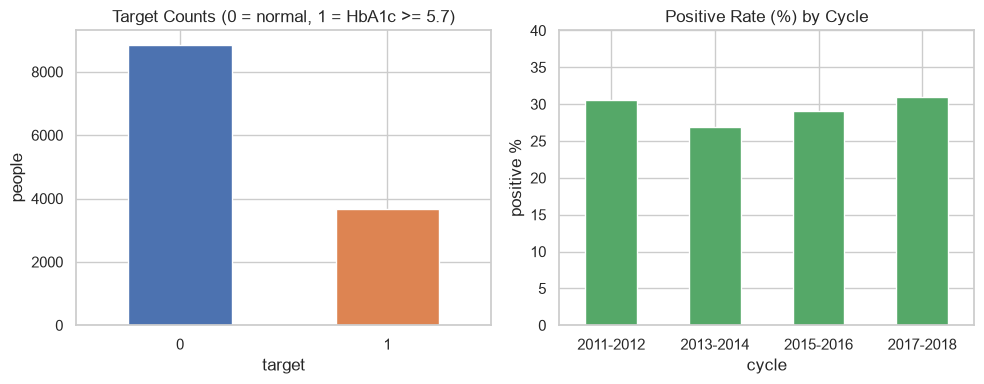

In [6]:
# count how many 0 and 1 we have in target
target_counts = df["target"].value_counts().sort_index()
target_pct = df["target"].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"count": target_counts, "percent": target_pct.round(2)}))

# also check target rate for each 2-year cycle
cycle_target = df.groupby("cycle")["target"].agg(total="count", positives="sum", positive_rate="mean")
cycle_target["positive_pct"] = (cycle_target["positive_rate"] * 100).round(2)
display(cycle_target[["total", "positives", "positive_pct"]])

# plot overall target counts and positive rate by cycle
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
target_counts.plot(kind="bar", ax=axes[0], color=["#4c72b0", "#dd8452"])
axes[0].set_title("Target Counts (0 = normal, 1 = HbA1c >= 5.7)")
axes[0].set_xlabel("target")
axes[0].set_ylabel("people")
axes[0].tick_params(axis="x", rotation=0)

(cycle_target["positive_rate"] * 100).plot(kind="bar", ax=axes[1], color="#55a868")
axes[1].set_title("Positive Rate (%) by Cycle")
axes[1].set_xlabel("cycle")
axes[1].set_ylabel("positive %")
axes[1].set_ylim(0, 40)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


## 3. Missing Values (by Reason)

Some columns are empty because a question was only in some years, or only asked to some people (like age 30+ or smokers). Here we separate those from real missing values.


In [7]:
# list of all 63 feature columns
feature_cols = [c for c in df.columns if c not in ["cycle", "seqn", "target"]]

# group columns by why they have missing values
cycle_only_cols = {
    "daytime_sleepiness_frequency",
    "sleep_breathing_difficulty_frequency",
    "snoring_frequency",
    "loose_tooth_without_injury",
    "serious_vision_difficulty",
    "taste_difficulty_1y",
    "persistent_mouth_sensation_1y",
}
age_or_skip_cols = {
    "cigarettes_per_smoking_day",
    "drinks_per_drinking_day",
    "self_suspected_gum_disease",
    "mouth_aching_frequency_1y",
    "floss_days_7d",
    "reported_weight_change_10y_kg",
    "attempted_weight_loss_1y",
    "walking_difficulty_without_equipment",
}

def missing_reason(col):
    if col in cycle_only_cols:
        return "cycle_only"
    if col in age_or_skip_cols:
        return "age_or_skip"
    return "real_missing"

# build missing value table with target=0 vs target=1 comparison
rows = []
for col in feature_cols:
    na = df[col].isna()
    rows.append({
        "feature": col,
        "reason": missing_reason(col),
        "missing_count": int(na.sum()),
        "missing_pct": round(na.mean() * 100, 2),
        "missing_pct_t0": round(na[df["target"] == 0].mean() * 100, 2),
        "missing_pct_t1": round(na[df["target"] == 1].mean() * 100, 2),
    })

missing_df = pd.DataFrame(rows).sort_values("missing_pct", ascending=False).reset_index(drop=True)
print("columns with 0 missing:", int((missing_df["missing_count"] == 0).sum()))
print("columns with > 20% missing:", int((missing_df["missing_pct"] > 20).sum()))
display(missing_df.head(25))


columns with 0 missing: 3
columns with > 20% missing: 13


,feature,reason,missing_count,missing_pct,missing_pct_t0,missing_pct_t1
0,cigarettes_per_smoking_day,age_or_skip,9985,79.66,79.89,79.11
1,persistent_mouth_sensation_1y,cycle_only,8594,68.57,73.19,57.41
2,taste_difficulty_1y,cycle_only,8591,68.54,73.17,57.38
3,loose_tooth_without_injury,cycle_only,7267,57.98,60.82,51.12
4,snoring_frequency,cycle_only,7099,56.64,56.61,56.70
5,sleep_breathing_difficulty_frequency,cycle_only,6976,55.66,55.71,55.53
6,daytime_sleepiness_frequency,cycle_only,6666,53.18,53.61,52.15
7,drinks_per_drinking_day,age_or_skip,4472,35.68,32.60,43.11
8,reported_weight_change_10y_kg,age_or_skip,4433,35.37,42.86,17.29
9,serious_vision_difficulty,cycle_only,3230,25.77,25.30,26.91


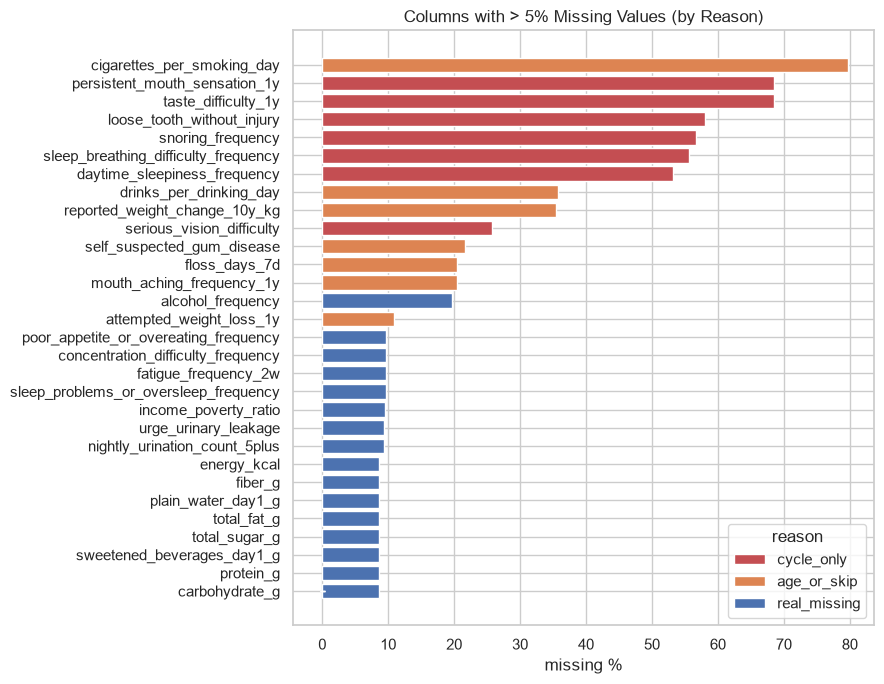

In [8]:
# plot columns that have more than 5% missing values
top_miss = missing_df[missing_df["missing_pct"] > 5].sort_values("missing_pct")
colors = {
    "cycle_only": "#c44e52",
    "age_or_skip": "#dd8452",
    "real_missing": "#4c72b0",
}

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_miss["feature"], top_miss["missing_pct"], color=top_miss["reason"].map(colors))
ax.set_title("Columns with > 5% Missing Values (by Reason)")
ax.set_xlabel("missing %")

# simple legend
for label, color in colors.items():
    ax.bar(0, 0, color=color, label=label)
ax.legend(title="reason", loc="lower right")

plt.tight_layout()
plt.show()


## 4. Numeric Features: Distribution and Outliers


In [9]:
# separate continuous numeric features from categorical / code features
numeric_cols = [
    "age", "income_poverty_ratio", "height_cm", "weight_kg", "bmi", "waist_cm",
    "waist_height_ratio", "systolic_mean", "diastolic_mean", "pulse",
    "work_activity_min_week", "leisure_activity_min_week", "transport_min_week",
    "sedentary_min_day", "cigarettes_per_smoking_day", "drinks_per_drinking_day",
    "sleep_workday_hours", "weight_1year_ago_kg", "energy_kcal", "carbohydrate_g",
    "protein_g", "total_fat_g", "total_sugar_g", "fiber_g", "plain_water_day1_g",
    "self_reported_weight_loss_1y_kg", "floss_days_7d",
    "reported_weight_change_10y_kg", "highest_ever_weight_kg",
    "away_from_home_meals_7d", "fast_food_pizza_meals_7d",
    "ready_to_eat_foods_30d", "frozen_meals_pizza_30d", "sweetened_beverages_day1_g",
]
cat_cols = [c for c in feature_cols if c not in numeric_cols]
print("numeric:", len(numeric_cols), "| categorical/ordinal:", len(cat_cols))

# check percentiles, skewness, and IQR outlier counts
num_rows = []
for col in numeric_cols:
    s = df[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    outliers = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
    num_rows.append({
        "feature": col,
        "min": round(s.min(), 2),
        "p1": round(s.quantile(0.01), 2),
        "median": round(s.median(), 2),
        "mean": round(s.mean(), 2),
        "p99": round(s.quantile(0.99), 2),
        "max": round(s.max(), 2),
        "skew": round(s.skew(), 2),
        "iqr_outliers": outliers,
    })

num_summary = pd.DataFrame(num_rows).sort_values("skew", ascending=False).reset_index(drop=True)
display(num_summary)


numeric: 34 | categorical/ordinal: 29


,feature,min,p1,median,mean,p99,max,skew,iqr_outliers
0,ready_to_eat_foods_30d,0.00,0.00,0.00,2.09,30.00,91.00,7.78,1101
1,transport_min_week,0.00,0.00,0.00,88.58,1440.00,5040.00,6.74,2507
2,frozen_meals_pizza_30d,0.00,0.00,0.00,2.40,30.00,91.00,6.71,1316
3,leisure_activity_min_week,0.00,0.00,30.00,159.02,1320.00,3540.00,3.86,1019
4,sweetened_beverages_day1_g,0.00,0.00,0.00,311.91,2338.30,6510.00,3.40,761
5,fast_food_pizza_meals_7d,0.00,0.00,1.00,1.65,14.00,22.00,3.06,876
6,work_activity_min_week,0.00,0.00,0.00,477.21,4800.00,8400.00,2.89,2069
7,drinks_per_drinking_day,1.00,1.00,2.00,2.75,12.00,30.00,2.86,448
8,total_sugar_g,0.00,10.04,97.48,114.00,393.42,1115.50,2.31,421
9,away_from_home_meals_7d,0.00,0.00,2.00,3.35,21.00,22.00,2.10,691


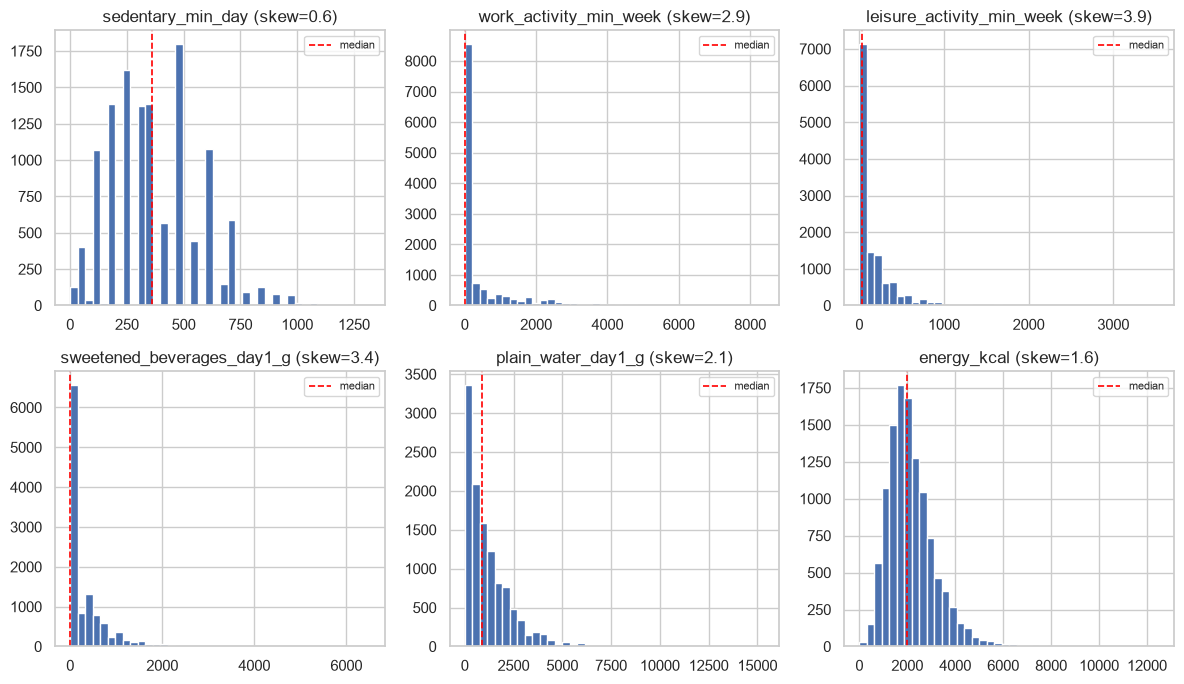

In [10]:
# plot distributions of some skewed numeric columns
skewed_cols = [
    "sedentary_min_day", "work_activity_min_week", "leisure_activity_min_week",
    "sweetened_beverages_day1_g", "plain_water_day1_g", "energy_kcal",
]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.ravel(), skewed_cols):
    s = df[col].dropna()
    ax.hist(s, bins=40, color="#4c72b0", edgecolor="white")
    ax.axvline(s.median(), color="red", linestyle="--", linewidth=1.2, label="median")
    ax.set_title(f"{col} (skew={s.skew():.1f})")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


## 5. Numeric Features vs Target


In [11]:
# compare numeric features between target=0 and target=1
diff_rows = []
for col in numeric_cols:
    g0 = df.loc[df["target"] == 0, col].dropna()
    g1 = df.loc[df["target"] == 1, col].dropna()
    pooled_std = np.sqrt((g0.var() + g1.var()) / 2)
    effect = (g1.mean() - g0.mean()) / pooled_std if pooled_std > 0 else 0.0
    diff_rows.append({
        "feature": col,
        "median_t0": round(g0.median(), 2),
        "median_t1": round(g1.median(), 2),
        "mean_t0": round(g0.mean(), 2),
        "mean_t1": round(g1.mean(), 2),
        "std_diff": round(effect, 3),
    })

diff_df = pd.DataFrame(diff_rows).sort_values("std_diff", key=abs, ascending=False).reset_index(drop=True)
display(diff_df.head(15))


,feature,median_t0,median_t1,mean_t0,mean_t1,std_diff
0,age,40.00,57.00,42.98,55.78,0.784
1,waist_height_ratio,0.56,0.61,0.57,0.62,0.538
2,systolic_mean,117.33,126.67,120.34,129.24,0.497
3,waist_cm,93.60,101.20,95.10,102.58,0.475
4,bmi,26.70,29.00,27.69,30.37,0.391
5,weight_kg,75.00,80.00,77.96,83.85,0.275
6,weight_1year_ago_kg,74.84,79.38,77.25,82.41,0.247
7,away_from_home_meals_7d,2.00,2.00,3.59,2.80,-0.207
8,highest_ever_weight_kg,81.65,84.59,84.52,89.00,0.196
9,reported_weight_change_10y_kg,2.27,4.54,2.93,5.27,0.191


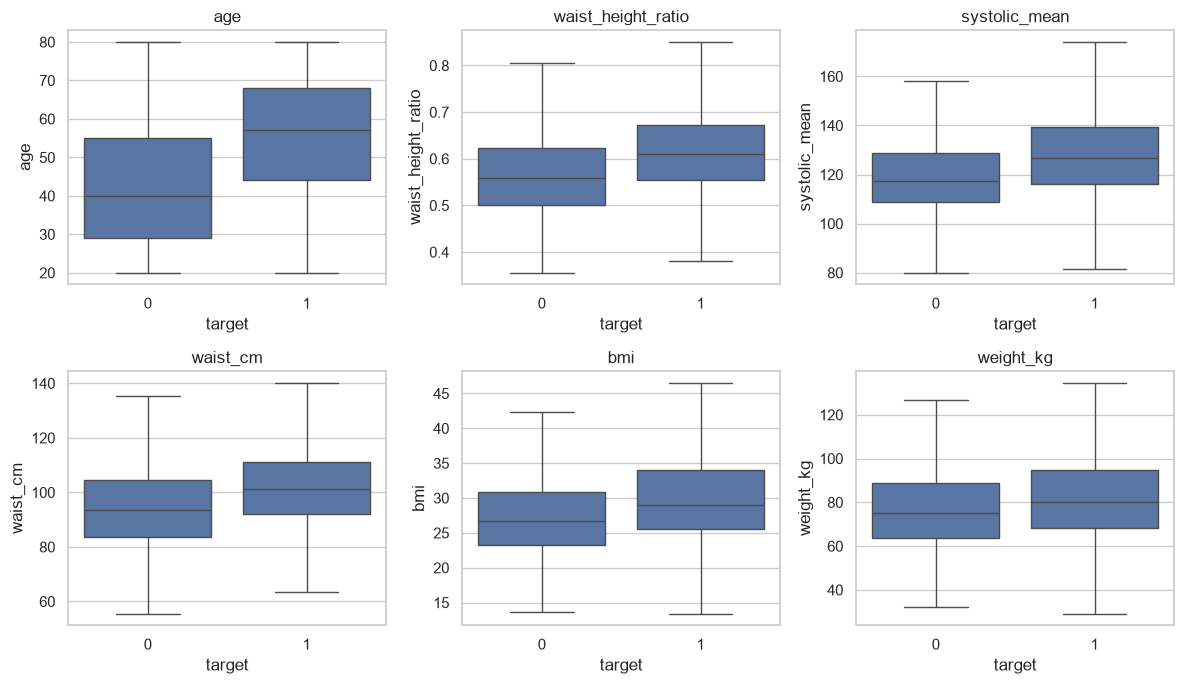

In [12]:
# boxplots for the top 6 numeric features that separate target=0 and target=1
top_num = diff_df["feature"].head(6).tolist()

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.ravel(), top_num):
    sns.boxplot(data=df, x="target", y=col, ax=ax, showfliers=False)
    ax.set_title(col)

plt.tight_layout()
plt.show()


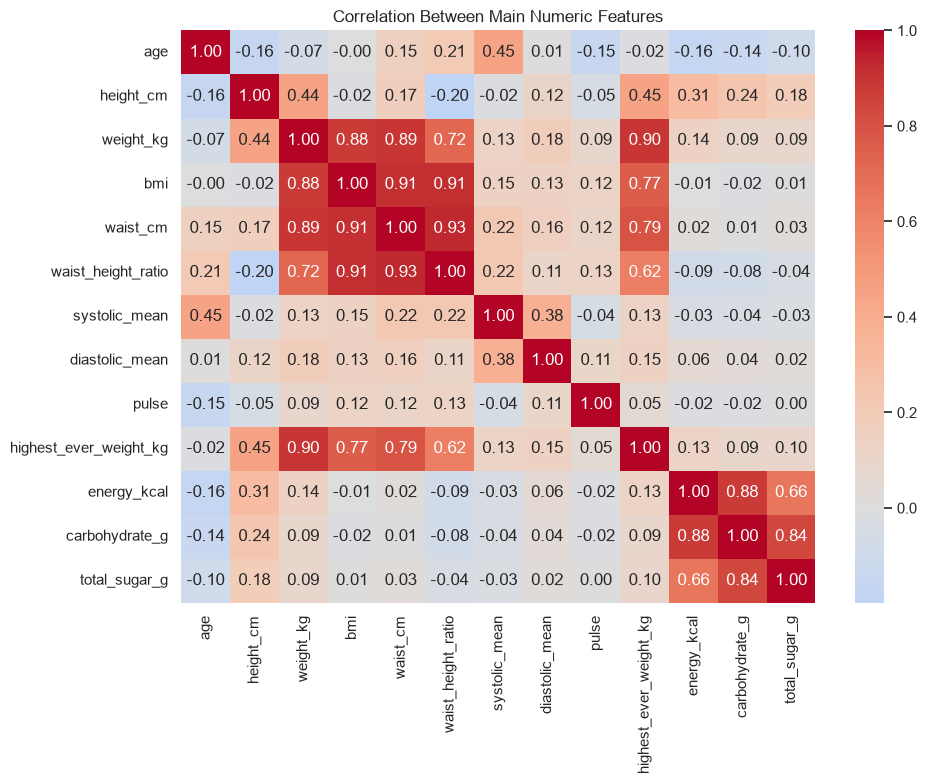

In [13]:
# check correlation between main body, blood pressure, and age columns
corr_cols = [
    "age", "height_cm", "weight_kg", "bmi", "waist_cm", "waist_height_ratio",
    "systolic_mean", "diastolic_mean", "pulse", "highest_ever_weight_kg",
    "energy_kcal", "carbohydrate_g", "total_sugar_g",
]
corr = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Between Main Numeric Features")
plt.tight_layout()
plt.show()


## 6. Categorical and Ordinal Features


In [14]:
# check value counts and positive rate for important categorical / ordinal columns
key_cats = [
    "sex", "education", "marital_status", "smoking_status", "family_diabetes",
    "self_rated_diet_quality", "adult_food_security", "employment_status_last_week",
    "self_rated_teeth_and_gums", "nightly_urination_count_5plus", "fatigue_frequency_2w",
]

for col in key_cats:
    tbl = df.groupby(col, dropna=False)["target"].agg(count="count", positive_rate="mean")
    tbl["positive_pct"] = (tbl["positive_rate"] * 100).round(1)
    print(f"--- {col} ---")
    print(tbl[["count", "positive_pct"]].to_string())
    print()


--- sex ---
     count  positive_pct
sex                     
1.0   6085          30.4
2.0   6449          28.2

--- education ---
           count  positive_pct
education                     
1.0         1043          45.1
2.0         1536          33.7
3.0         2789          31.5
4.0         3883          26.4
5.0         3276          23.7
NaN            7          71.4

--- marital_status ---
                count  positive_pct
marital_status                     
1.0              6181          31.5
2.0               793          46.8
3.0              1288          34.8
4.0               416          35.1
5.0              2662          18.9
6.0              1189          21.4
NaN                 5          40.0

--- smoking_status ---
                count  positive_pct
smoking_status                     
0.0              7343          27.4
1.0              2598          33.9
2.0              2582          30.1
NaN                11          36.4

--- family_diabetes ---
        

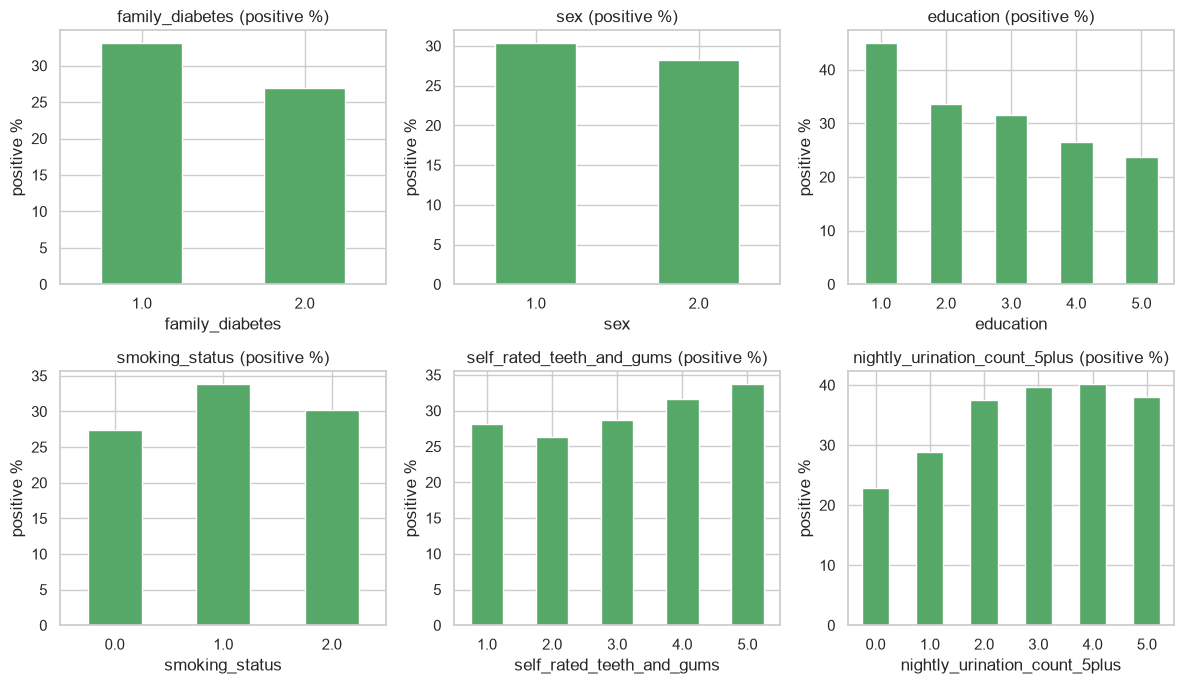

In [15]:
# plot positive rate (%) for 6 key categorical / ordinal columns
plot_cats = [
    "family_diabetes", "sex", "education",
    "smoking_status", "self_rated_teeth_and_gums", "nightly_urination_count_5plus",
]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.ravel(), plot_cats):
    rates = df.groupby(col)["target"].mean() * 100
    rates.plot(kind="bar", ax=ax, color="#55a868")
    ax.set_title(f"{col} (positive %)")
    ax.set_ylabel("positive %")
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


## 7. Cycle Differences (2011-2018)

In NHANES, the survey questions for `sleep_workday_hours`, `alcohol_frequency`, and `smoking_inside_home` changed across cycles. Here we check if their values shift between 2011 and 2018.


--- sleep_workday_hours by cycle ---
           count  missing_pct  mean  median
cycle                                      
2011-2012   3225          0.1  6.82     7.0
2013-2014   3429          0.1  6.89     7.0
2015-2016   3050          0.5  7.67     8.0
2017-2018   2784          0.9  7.57     7.5

--- alcohol_frequency by cycle ---
           count  missing_pct  mean  median
cycle                                      
2011-2012   2459         23.8  1.93     2.0
2013-2014   2687         21.7  1.91     2.0
2015-2016   2304         24.8  1.90     2.0
2017-2018   2625          6.6  1.52     1.0

--- smoking_inside_home by cycle ---
           count  missing_pct  mean  median
cycle                                      
2011-2012   3224          0.2  0.14     0.0
2013-2014   3388          1.3  0.15     0.0
2015-2016   2975          2.9  0.12     0.0
2017-2018   2682          4.6  0.13     0.0



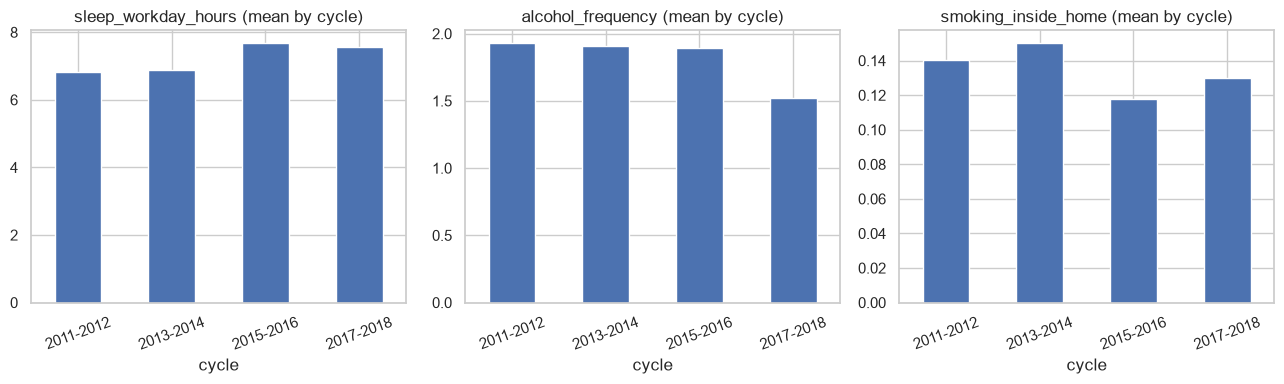

In [16]:
# check mean and missing % by cycle for the 3 columns where questions changed
drift_cols = ["sleep_workday_hours", "alcohol_frequency", "smoking_inside_home"]

for col in drift_cols:
    tbl = df.groupby("cycle")[col].agg(
        count="count",
        missing_pct=lambda s: round(s.isna().mean() * 100, 1),
        mean="mean",
        median="median",
    )
    tbl["mean"] = tbl["mean"].round(2)
    print(f"--- {col} by cycle ---")
    print(tbl.to_string())
    print()

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, drift_cols):
    df.groupby("cycle")[col].mean().plot(kind="bar", ax=ax, color="#4c72b0")
    ax.set_title(f"{col} (mean by cycle)")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


## 8. Notes for Preprocessing

- **Target balance:** About 29.3% positive in train, and stable across all 4 cycles.
- **Missing values:** Do not treat all missing values the same. Cycle-only columns have ~50% missing, and age/skip columns (like smoking/drinking counts or age 30+ dental questions) are empty on purpose.
- **Skewed numeric columns:** Activity minutes, sedentary minutes, and drink/water grams are strongly right-skewed.
- **High correlation:** `weight_kg`, `bmi`, `waist_cm`, `waist_height_ratio`, and `highest_ever_weight_kg` are strongly correlated (important to remember for Logistic Regression).
- **Cycle drift:** Check whether `sleep_workday_hours`, `alcohol_frequency`, and `smoking_inside_home` shift in newer cycles when we test features in Step 3.
